In [1]:
import os
for dirpath, _, files in os.walk('/kaggle/input'):
    for f in files:
        print(os.path.join(dirpath, f))

/kaggle/input/datasets/medaminebougadouha/sarcos-inverse-dynamics/sarcos_inv.mat
/kaggle/input/datasets/medaminebougadouha/sarcos-inverse-dynamics/sarcos_inv_test.mat


In [2]:
import os, glob, time
import numpy as np
import pandas as pd
import scipy.io as sio
import matplotlib.pyplot as plt

np.random.seed(42)   # pour avoir toujours les mêmes résultats
print("Outils chargés")

Outils chargés


In [3]:
path_train = glob.glob('/kaggle/input/**/sarcos_inv.mat', recursive=True)[0]
path_test  = glob.glob('/kaggle/input/**/sarcos_inv_test.mat', recursive=True)[0]
print("Train :", path_train)
print("Test  :", path_test)

Train : /kaggle/input/datasets/medaminebougadouha/sarcos-inverse-dynamics/sarcos_inv.mat
Test  : /kaggle/input/datasets/medaminebougadouha/sarcos-inverse-dynamics/sarcos_inv_test.mat


In [4]:
mat_train = sio.loadmat(path_train)
mat_test  = sio.loadmat(path_test)

print("Clés du fichier train :", [k for k in mat_train.keys() if not k.startswith('__')])
print("Clés du fichier test  :", [k for k in mat_test.keys() if not k.startswith('__')])

train = mat_train['sarcos_inv']
test  = mat_test['sarcos_inv_test']

print("train :", train.shape)
print("test  :", test.shape)

Clés du fichier train : ['sarcos_inv']
Clés du fichier test  : ['sarcos_inv_test']
train : (44484, 28)
test  : (4449, 28)


In [5]:
X_all      = train[:, :21]    # les 21 premières colonnes = entrées
Y_all      = train[:, 21:]    # les 7 dernières colonnes = couples
X_test_raw = test[:, :21]
Y_test_all = test[:, 21:]

print("X_all :", X_all.shape, "| Y_all :", Y_all.shape)
print("X_test_raw :", X_test_raw.shape, "| Y_test_all :", Y_test_all.shape)

X_all : (44484, 21) | Y_all : (44484, 7)
X_test_raw : (4449, 21) | Y_test_all : (4449, 7)


In [6]:
noms = [f"pos_{i}" for i in range(1, 8)] + \
       [f"vel_{i}" for i in range(1, 8)] + \
       [f"acc_{i}" for i in range(1, 8)]

df = pd.DataFrame(X_all, columns=noms)
df["couple_1"] = Y_all[:, 0]

print("Valeurs manquantes :", df.isna().sum().sum())
df.describe().T.round(3)

Valeurs manquantes : 0


,count,mean,std,min,25%,50%,75%,max
pos_1,44484.0,-0.172,0.299,-0.845,-0.408,-0.197,0.068,0.662
pos_2,44484.0,-0.350,0.126,-0.941,-0.409,-0.339,-0.266,-0.085
pos_3,44484.0,0.012,0.131,-0.478,-0.057,0.024,0.103,0.366
pos_4,44484.0,1.617,0.231,0.755,1.461,1.642,1.786,2.257
pos_5,44484.0,0.269,0.281,-0.244,0.012,0.292,0.455,1.294
pos_6,44484.0,-0.061,0.213,-0.921,-0.141,0.004,0.084,0.371
pos_7,44484.0,0.204,0.176,-0.301,0.073,0.195,0.331,0.691
vel_1,44484.0,0.006,1.115,-4.802,-0.332,-0.000,0.335,4.707
vel_2,44484.0,-0.001,0.474,-1.646,-0.305,0.000,0.274,2.289
vel_3,44484.0,-0.001,0.595,-2.966,-0.323,-0.008,0.353,2.558


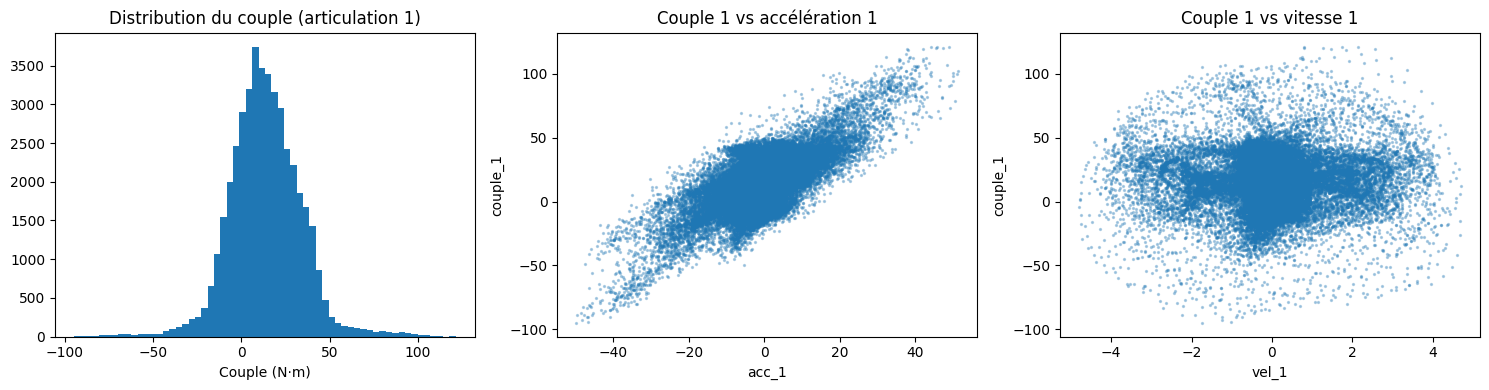

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

ax[0].hist(Y_all[:, 0], bins=60)
ax[0].set_title("Distribution du couple (articulation 1)")
ax[0].set_xlabel("Couple (N·m)")

ax[1].scatter(X_all[:, 14], Y_all[:, 0], s=2, alpha=0.3)
ax[1].set_title("Couple 1 vs accélération 1")
ax[1].set_xlabel("acc_1"); ax[1].set_ylabel("couple_1")

ax[2].scatter(X_all[:, 7], Y_all[:, 0], s=2, alpha=0.3)
ax[2].set_title("Couple 1 vs vitesse 1")
ax[2].set_xlabel("vel_1"); ax[2].set_ylabel("couple_1")

plt.tight_layout()
os.makedirs('/kaggle/working/results', exist_ok=True)
plt.savefig('/kaggle/working/results/01_exploration.png', dpi=150)
plt.show()

In [8]:
from sklearn.model_selection import train_test_split

# Cible : couple de l'articulation 1 (colonne 0 de Y)
y_all  = Y_all[:, 0]
y_test = Y_test_all[:, 0]

# 90 % entraînement, 10 % validation
X_tr, X_val, y_tr, y_val = train_test_split(
    X_all, y_all, test_size=0.1, random_state=42)

print("Entraînement :", X_tr.shape, y_tr.shape)
print("Validation   :", X_val.shape, y_val.shape)
print("Test         :", X_test_raw.shape, y_test.shape)

Entraînement : (40035, 21) (40035,)
Validation   : (4449, 21) (4449,)
Test         : (4449, 21) (4449,)


In [9]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(X_tr)     # on apprend l'échelle UNIQUEMENT sur le train

X_tr_s   = scaler.transform(X_tr)
X_val_s  = scaler.transform(X_val)
X_test_s = scaler.transform(X_test_raw)

print("Moyenne des colonnes (train) :", X_tr_s.mean(axis=0).round(2)[:5], "...")
print("Écart-type des colonnes (train) :", X_tr_s.std(axis=0).round(2)[:5], "...")

Moyenne des colonnes (train) : [-0.  0.  0. -0.  0.] ...
Écart-type des colonnes (train) : [1. 1. 1. 1. 1.] ...


In [10]:
def nmse(y_true, y_pred):
    """Erreur quadratique moyenne normalisée par la variance de y_true."""
    return np.mean((y_true - y_pred) ** 2) / np.var(y_true)

def rmse(y_true, y_pred):
    """Erreur moyenne en N·m."""
    return np.sqrt(np.mean((y_true - y_pred) ** 2))

# Petit test pour vérifier : prédire toujours la moyenne doit donner nMSE ≈ 1
test_naif = np.full_like(y_val, y_tr.mean())
print("nMSE si on prédit toujours la moyenne :", round(nmse(y_val, test_naif), 4))

nMSE si on prédit toujours la moyenne : 1.0002


In [11]:
from sklearn.linear_model import LinearRegression

lin = LinearRegression().fit(X_tr_s, y_tr)

pred_val_lin = lin.predict(X_val_s)

t0 = time.time()
pred_test_lin = lin.predict(X_test_s)
t_lin = (time.time() - t0) / len(X_test_s) * 1000   # ms par échantillon

print(f"Linéaire  nMSE validation : {nmse(y_val, pred_val_lin):.4f}")
print(f"Linéaire  nMSE test       : {nmse(y_test, pred_test_lin):.4f}")
print(f"Linéaire  RMSE test       : {rmse(y_test, pred_test_lin):.3f} N·m")
print(f"Temps d'inférence         : {t_lin:.5f} ms/échantillon")

Linéaire  nMSE validation : 0.0771
Linéaire  nMSE test       : 0.0751
Linéaire  RMSE test       : 5.576 N·m
Temps d'inférence         : 0.00015 ms/échantillon


acc_1    24.253
acc_4     9.955
pos_1     8.135
pos_4    -2.941
acc_5    -2.231
acc_2    -1.768
pos_6     1.561
acc_3    -1.561
dtype: float64


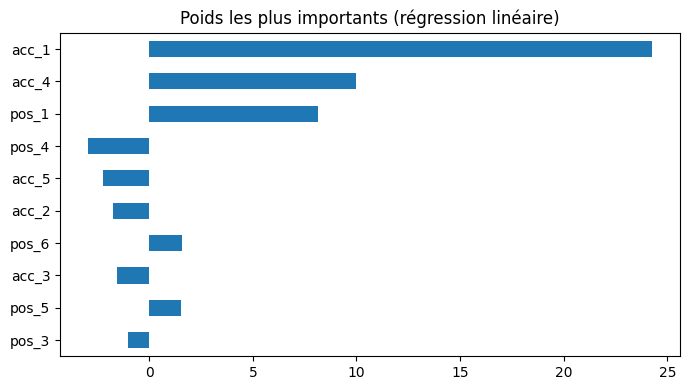

In [12]:
coef = pd.Series(lin.coef_, index=noms).sort_values(key=abs, ascending=False)
print(coef.head(8).round(3))

coef.head(10).plot(kind='barh', figsize=(7, 4))
plt.title("Poids les plus importants (régression linéaire)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('/kaggle/working/results/02_coef_lineaire.png', dpi=150)
plt.show()

In [13]:
from sklearn.neural_network import MLPRegressor
import warnings
warnings.filterwarnings("ignore")

mlp = MLPRegressor(hidden_layer_sizes=(128, 128),   # 2 couches de 128 neurones
                   activation='relu',
                   solver='adam',
                   learning_rate_init=1e-3,
                   early_stopping=True,              # s'arrête quand ça ne s'améliore plus
                   validation_fraction=0.1,
                   n_iter_no_change=10,
                   max_iter=200,
                   random_state=42)

t0 = time.time()
mlp.fit(X_tr_s, y_tr)
print(f"Entraînement : {time.time() - t0:.1f} s | epochs effectuées : {mlp.n_iter_}")
print(f"MLP (128,128)  nMSE validation : {nmse(y_val, mlp.predict(X_val_s)):.4f}")
print(f"Pour comparaison, linéaire     : {nmse(y_val, pred_val_lin):.4f}")

Entraînement : 54.6 s | epochs effectuées : 124
MLP (128,128)  nMSE validation : 0.0157
Pour comparaison, linéaire     : 0.0771


In [14]:
architectures = [(32,), (64,), (64, 64), (128, 128), (256, 256)]
resultats = []
modeles = {}

for arch in architectures:
    m = MLPRegressor(hidden_layer_sizes=arch, activation='relu',
                     early_stopping=True, n_iter_no_change=10,
                     max_iter=200, random_state=42)
    t0 = time.time()
    m.fit(X_tr_s, y_tr)
    t_train = time.time() - t0
    score_val = nmse(y_val, m.predict(X_val_s))
    modeles[arch] = m
    resultats.append({"architecture": arch,
                      "nMSE_val": round(score_val, 4),
                      "epochs": m.n_iter_,
                      "temps_train_s": round(t_train, 1)})
    print(arch, "→ nMSE val =", round(score_val, 4), f"({t_train:.0f} s)")

df_res = pd.DataFrame(resultats).sort_values("nMSE_val").reset_index(drop=True)
df_res

(32,) → nMSE val = 0.028 (18 s)
(64,) → nMSE val = 0.0241 (24 s)
(64, 64) → nMSE val = 0.0197 (23 s)
(128, 128) → nMSE val = 0.0157 (54 s)
(256, 256) → nMSE val = 0.014 (90 s)


,architecture,nMSE_val,epochs,temps_train_s
0,"(256, 256)",0.0140,84,89.5
1,"(128, 128)",0.0157,124,53.7
2,"(64, 64)",0.0197,96,23.1
3,"(64,)",0.0241,169,23.7
4,"(32,)",0.0280,157,17.7


In [15]:
meilleure_arch = df_res.loc[0, "architecture"]
best = modeles[meilleure_arch]
print("Meilleure architecture (choisie sur la validation) :", meilleure_arch)

t0 = time.time()
pred_test_mlp = best.predict(X_test_s)
t_mlp = (time.time() - t0) / len(X_test_s) * 1000   # ms par échantillon

final = pd.DataFrame([
    {"modèle": "Régression linéaire",
     "nMSE_test": nmse(y_test, pred_test_lin),
     "RMSE_test (N·m)": rmse(y_test, pred_test_lin),
     "ms/échantillon": t_lin},
    {"modèle": f"MLP {meilleure_arch}",
     "nMSE_test": nmse(y_test, pred_test_mlp),
     "RMSE_test (N·m)": rmse(y_test, pred_test_mlp),
     "ms/échantillon": t_mlp},
]).round(5)

os.makedirs('/kaggle/working/results', exist_ok=True)
final.to_csv('/kaggle/working/results/tableau_final.csv', index=False)
df_res.to_csv('/kaggle/working/results/comparaison_architectures.csv', index=False)
final

Meilleure architecture (choisie sur la validation) : (256, 256)


,modèle,nMSE_test,RMSE_test (N·m),ms/échantillon
0,Régression linéaire,0.07508,5.57623,0.00015
1,"MLP (256, 256)",0.01070,2.10522,0.00882


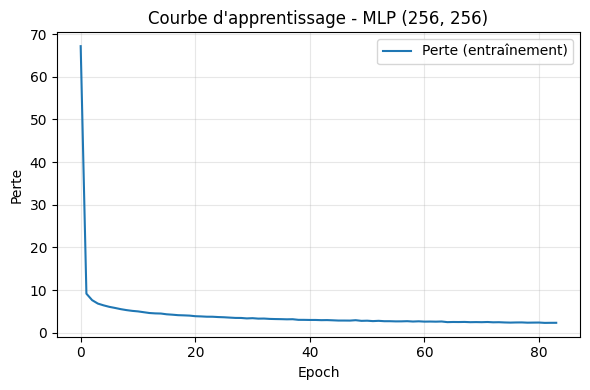

In [16]:
plt.figure(figsize=(6, 4))
plt.plot(best.loss_curve_, label="Perte (entraînement)")
plt.xlabel("Epoch")
plt.ylabel("Perte")
plt.title(f"Courbe d'apprentissage - MLP {meilleure_arch}")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('/kaggle/working/results/03_courbe_apprentissage.png', dpi=150)
plt.show()

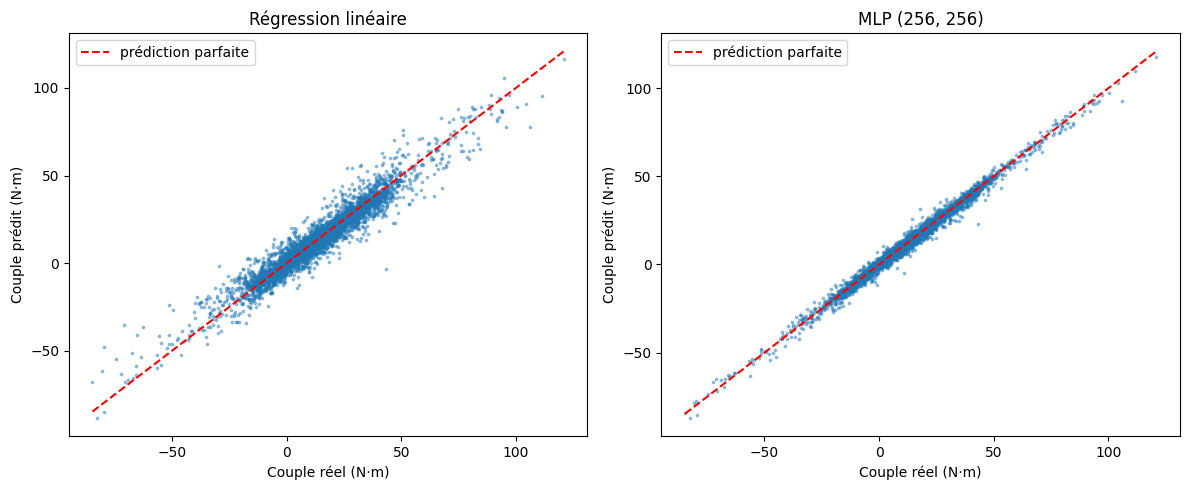

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, pred, titre in zip(ax, [pred_test_lin, pred_test_mlp],
                          ["Régression linéaire", f"MLP {meilleure_arch}"]):
    a.scatter(y_test, pred, s=3, alpha=0.4)
    lim = [y_test.min(), y_test.max()]
    a.plot(lim, lim, 'r--', label="prédiction parfaite")
    a.set_xlabel("Couple réel (N·m)")
    a.set_ylabel("Couple prédit (N·m)")
    a.set_title(titre)
    a.legend()
plt.tight_layout()
plt.savefig('/kaggle/working/results/04_predit_vs_reel.png', dpi=150)
plt.show()

In [18]:
erreur = np.abs(y_test - pred_test_mlp)
print(f"Erreur absolue moyenne : {erreur.mean():.3f} N·m")
print(f"Erreur médiane         : {np.median(erreur):.3f} N·m")
print(f"90 % des erreurs sont sous : {np.percentile(erreur, 90):.3f} N·m")
print(f"Erreur maximale        : {erreur.max():.3f} N·m")

# On range les échantillons selon l'accélération |acc_1| en 4 groupes égaux
acc_abs = np.abs(X_test_raw[:, 14])
vel_abs = np.abs(X_test_raw[:, 7])
groupes_acc = pd.qcut(acc_abs, 4, labels=["très faible", "faible", "forte", "très forte"])
groupes_vel = pd.qcut(vel_abs, 4, labels=["très faible", "faible", "forte", "très forte"])

print("\nErreur moyenne selon l'accélération |acc_1| :")
print(pd.Series(erreur).groupby(groupes_acc).mean().round(3))
print("\nErreur moyenne selon la vitesse |vel_1| :")
print(pd.Series(erreur).groupby(groupes_vel).mean().round(3))

Erreur absolue moyenne : 1.501 N·m
Erreur médiane         : 1.094 N·m
90 % des erreurs sont sous : 3.331 N·m
Erreur maximale        : 20.035 N·m

Erreur moyenne selon l'accélération |acc_1| :
très faible    1.301
faible         1.364
forte          1.534
très forte     1.807
dtype: float64

Erreur moyenne selon la vitesse |vel_1| :
très faible    1.522
faible         1.640
forte          1.529
très forte     1.315
dtype: float64


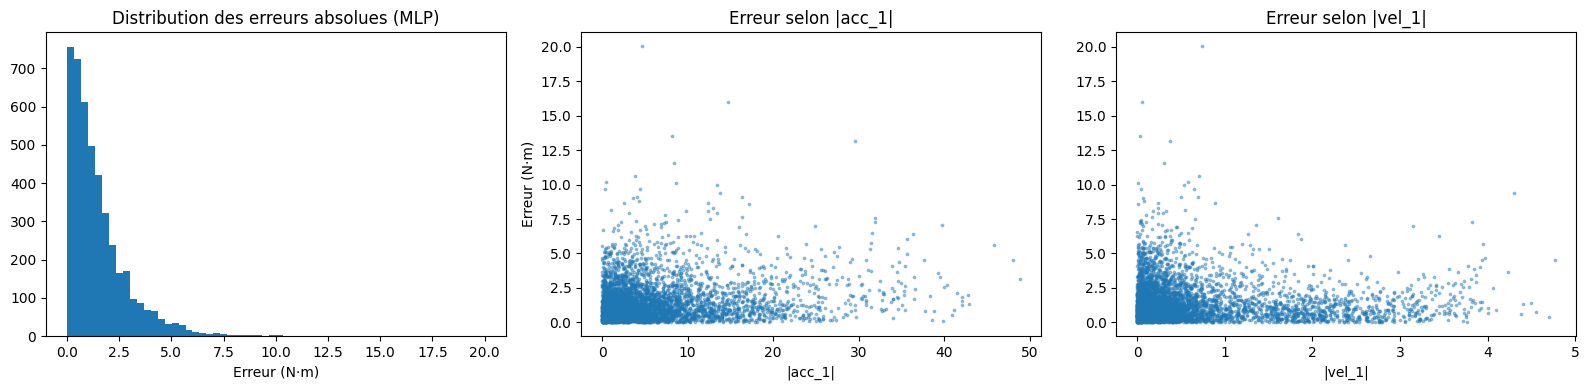

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

ax[0].hist(erreur, bins=60)
ax[0].set_title("Distribution des erreurs absolues (MLP)")
ax[0].set_xlabel("Erreur (N·m)")

ax[1].scatter(acc_abs, erreur, s=3, alpha=0.4)
ax[1].set_title("Erreur selon |acc_1|")
ax[1].set_xlabel("|acc_1|")
ax[1].set_ylabel("Erreur (N·m)")

ax[2].scatter(vel_abs, erreur, s=3, alpha=0.4)
ax[2].set_title("Erreur selon |vel_1|")
ax[2].set_xlabel("|vel_1|")

plt.tight_layout()
plt.savefig('/kaggle/working/results/05_analyse_erreurs.png', dpi=150)
plt.show()

In [20]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42)
t0 = time.time()
rf.fit(X_tr_s, y_tr)
print(f"Entraînement RF : {time.time() - t0:.0f} s")

pred_val_rf = rf.predict(X_val_s)
pred_test_rf = rf.predict(X_test_s)
print(f"Random Forest  nMSE val  : {nmse(y_val, pred_val_rf):.4f}")
print(f"Random Forest  nMSE test : {nmse(y_test, pred_test_rf):.4f}")
print(f"Random Forest  RMSE test : {rmse(y_test, pred_test_rf):.3f} N·m")

Entraînement RF : 56 s
Random Forest  nMSE val  : 0.0251
Random Forest  nMSE test : 0.0055
Random Forest  RMSE test : 1.504 N·m


In [21]:
import shutil
shutil.make_archive('/kaggle/working/results_sarcos', 'zip', '/kaggle/working/results')
print(os.listdir('/kaggle/working/results'))

['03_courbe_apprentissage.png', '05_analyse_erreurs.png', '04_predit_vs_reel.png', 'comparaison_architectures.csv', '01_exploration.png', 'tableau_final.csv', '02_coef_lineaire.png']
